# Figure 5 — a smooth pulse at $L = 10000$

One long run from a Gaussian-smoothed initial guess, to show the geodesic step
holds up when the pulse is orders of magnitude longer than the gate count.

**Units.** A coefficient is a phase per segment, $\phi = h\,\Delta t$ ($\hbar = 1$), so the
physics enters through $\Delta t = T/L$. We use Rydberg-atom scales: a $T = 500$ ns gate,
a fixed ZZ coupling $J/2\pi = 1$ MHz ($JT = \pi$, four times the $\pi/4$ a CNOT needs),
local drives of a few MHz, and a 10 ns smoothing width. $L = 10000$ then means a
$\Delta t = 50$ ps time step.


In [ ]:
from common import *

In [ ]:
def gaussian_kernel(width, n_sigma=3):
    r"""A Gaussian smoothing kernel of **unit sum**, as a 1-D array
    Args:
        width: The Gaussian's standard deviation, in gate segments.
        n_sigma: Half-width of the truncated support, in units of ``width``.

    Returns:
        A ``(2 * radius + 1,)`` array summing to 1, with
        ``radius = ceil(n_sigma * width)``.
    """
    radius = max(1, int(np.ceil(n_sigma * width)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / width) ** 2)
    return kernel / kernel.sum()

def smooth_along_time(fields, width, n_sigma=3, match_rms=True):
    r"""Smooth each control field along the gate axis, from zero back to zero

    Args:
        fields: ``(L, K_proj)`` array; column ``k`` is one control's time trace.
        width: Gaussian sigma in gate segments.
        n_sigma: Half-width of the kernel support, in units of ``width``. It
            sets the ramp length too, the two being the same number.
        match_rms: Rescale to the live-window RMS of ``fields``. Right for a
            white-noise draw, whose power the kernel removes; wrong for a pulse
            that is already smooth, which the kernel leaves at its amplitude.

    Returns:
        A ``(L, K_proj)`` array whose first and last rows are exactly zero.

    Raises:
        ValueError: If the two ramps leave no live window between them, i.e.
            ``2 * (radius + 1) >= L``.
    """
    if not width:
        return fields
    steps = fields.shape[0]
    kernel = gaussian_kernel(width, n_sigma)
    margin = (kernel.size - 1) // 2 + 1
    if 2 * margin >= steps:
        raise ValueError(
            f"sigma = {width:g} over {n_sigma} sigma needs {2 * margin} segments "
            f"of ramp, which is all of L = {steps}"
        )
    live = slice(margin, steps - margin)
    gated = np.zeros_like(fields)
    gated[live] = fields[live]
    smoothed = np.stack(
        [np.convolve(gated[:, k], kernel, "same") for k in range(fields.shape[1])],
        axis=1,
    )
    scale = np.sqrt(np.mean(smoothed[live] ** 2))
    if not match_rms or scale == 0:
        return smoothed
    return smoothed * (np.sqrt(np.mean(fields[live] ** 2)) / scale)

def smooth_pulse(params, rng, spread, width):
    """`random_pulse`, band-limited along the time axis and zero at both ends.

    The same draw as `random_pulse` for a given ``rng``, convolved with
    `gaussian_kernel` under zero boundary conditions: a physically plausible
    guess for hardware with finite bandwidth, which must also switch the drive
    on and off. Only the controllable columns are smoothed -- the drift columns
    are not ours to shape, and `Geope` overwrites them anyway.
    """
    pulse = random_pulse(params, rng, spread)
    columns = params.projected_indices
    pulse[:, columns] = smooth_along_time(pulse[:, columns], width)
    return pulse


In [ ]:
N_QUBITS_L = 2
TARGET_L = "CNOT"
L_LARGE = 10000

# Physical scales (Rydberg). 
T_GATE = 500e-9  # s, total gate time
J_ZZ = 2 * np.pi * 1e6  # rad/s, the fixed ZZ coupling (J / 2pi = 1 MHz)
OMEGA_MAX = 2 * np.pi * 5e6  # rad/s, peak drive of the initial guess
SIGMA_TIME = 10e-9  # s, Gaussian smoothing width (bandwidth ~ 1/(2 pi sigma) = 16 MHz)
DT = T_GATE / L_LARGE  # s, one segment

SMOOTH_SIGMA = SIGMA_TIME / DT  # Gaussian sigma, in gate segments
SPREAD_L = OMEGA_MAX * DT / np.pi  # `random_pulse` draws on [-pi spread, pi spread]
DRIFT_L = np.array([J_ZZ * DT])  # ZZ phase per segment
MAX_STEP_L = 1.0
LARGE_SEED = 0
LARGE_LINE_SEARCH = Armijo()


def large_config(n, target, steps, sigma, spread, seed):
    """Everything that changes this block's numbers"""
    return {
        "tag": (
            f"large_{target}_L{steps}_T{T_GATE * 1e9:g}ns_J{J_ZZ / 2 / np.pi / 1e6:g}MHz"
            f"_sigma{sigma:g}_{spread_slug(spread)}"
        ),
        "kind": "large-L-smooth",
        "n_qubits": n,
        "target": target,
        "steps": steps,
        "sigma": sigma,
        "spread": spread,
        "seed": seed,
        "t_gate_s": T_GATE,
        "j_zz_rad_per_s": J_ZZ,
        "dt_s": DT,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
        "line_search": repr(LARGE_LINE_SEARCH),
        "geope_max_step": MAX_STEP_L,
        "smoothing": "unit-sum kernel, zero boundary, rescaled to live RMS",
    }


def large_paths(cfg):
    """``(npz, json)`` for this block — one folder for the whole figure.

    Not one folder per anything: this is a *single* run, not a sweep, so the
    three-deep nesting Figures 2 and 4 need would be one directory per file.
    """
    return cache_paths(cfg, "large")


def large_run(force=False, verbose=True):
    """The one run, reading the cache. Returns ``(block, note)``.
    """
    cfg = large_config(
        N_QUBITS_L, TARGET_L, L_LARGE, SMOOTH_SIGMA, SPREAD_L, LARGE_SEED
    )
    npz_path, json_path = large_paths(cfg)
    if npz_path.exists() and not force:
        with np.load(npz_path) as handle:
            return {k: handle[k] for k in handle.files}, "cached"

    params = make_parameters_cnot(
        L_LARGE, TARGET_L, spread=SPREAD_L, drift_values=DRIFT_L
    )
    columns = params.projected_indices
    # The same draw twice: `smooth_pulse` *is* `random_pulse` convolved, so
    # seeding both with a fresh generator is what makes `white` the unsmoothed
    # version of `init` rather than an unrelated pulse.
    white = random_pulse(params, np.random.default_rng(LARGE_SEED), SPREAD_L)
    init = smooth_pulse(
        params, np.random.default_rng(LARGE_SEED), SPREAD_L, SMOOTH_SIGMA
    )

    optimiser = Geope(params, history=History())
    if verbose:
        print(f"  {cfg['tag']:44s} computing", flush=True)
    started = time.perf_counter()
    # No `warm_up`: one run pays one JIT trace either way, and charging it to
    # the run is what the per-step clock below is there to separate out.
    fidelity, seconds = timed_trajectory(
        optimiser,
        init,
        LARGE_LINE_SEARCH,
        label=TARGET_L if verbose else "",
        max_step_size=MAX_STEP_L,
    )
    block = {
        "fidelity": fidelity,
        "seconds": seconds,
        "white": np.asarray(white)[:, columns],
        "init": np.asarray(init)[:, columns],
        "final": np.asarray(params.parameters)[:, columns],
        "labels": np.array(list(params.projected_basis.labels)),
        "n_free": np.asarray(params.free().size),
    }
    npz_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(npz_path, **block)
    json_path.write_text(
        json.dumps(
            {**cfg, "steps_taken": int(fidelity.size - 1)}, indent=1, sort_keys=True
        )
    )
    return block, f"computed in {time.perf_counter() - started:.0f}s"


large, large_note = large_run()
fidelity = large["fidelity"]
white, init, final = large["white"], large["init"], large["final"]
labels = [str(s) for s in large["labels"]]
n_free = int(large["n_free"])
seconds = large["seconds"]
n_taken = fidelity.size - 1  
per_step = np.diff(seconds)

print(f"target      : {TARGET_L} on {N_QUBITS_L} atoms, L = {L_LARGE}  ({large_note})")
print(
    f"units       : T = {T_GATE * 1e9:g} ns, dt = {DT * 1e12:g} ps, "
    f"J/2pi = {J_ZZ / 2 / np.pi / 1e6:g} MHz (J T = {J_ZZ * T_GATE / np.pi:g} pi)"
)
print(f"parameters  : P = {n_free}")
print(f"steps       : {n_taken} of at most {MAX_STEPS}")
print(
    f"wall clock  : {float(seconds[-1]):.1f} s total, of which "
    f"{float(per_step[0]) * 1e3:.0f} ms is step 1 (the JIT trace);\n"
    f"              {float(np.median(per_step[1:])) * 1e3:.0f} ms/step thereafter"
)
print(f"infidelity  : {1 - fidelity[-1]:.3e}   (converged: {fidelity[-1] > PRECISION})")
print(
    f"roughness   : {roughness(white):.3f} white -> {roughness(init):.3f} smoothed "
    f"-> {roughness(final):.3f} optimised"
)
# The headline number, and the reason panel (b) draws one pulse and not two:
# at this L the guess and the solution coincide at plotting resolution.
shift = np.sqrt(np.mean((final - init) ** 2)) / np.sqrt(np.mean(init**2))
print(
    f"displaced   : {100 * shift:.1f}% of the guess in RMS "
    f"(max |delta| = {np.abs(final - init).max():.1e})"
)
# Exactly zero in the guess, by construction; nothing holds them there during
# the run, so this is the honest check that the run does not walk them off.
ends = np.abs(np.asarray([init[0], init[-1], final[0], final[-1]]))
print(
    f"ends        : max |amplitude| at segments 0 and L-1 is "
    f"{ends[:2].max():.1e} in the guess -> {ends[2:].max():.1e} optimised, "
    f"against an RMS amplitude of {np.sqrt(np.mean(final**2)):.3f}"
)
to_mhz = 1 / DT / (2 * np.pi) / 1e6  # phase per segment -> h / 2pi in MHz
print(
    f"amplitude   : peak |h|/2pi = {np.abs(init).max() * to_mhz:.2f} MHz guess -> "
    f"{np.abs(final).max() * to_mhz:.2f} MHz optimised "
    f"(RMS {np.sqrt(np.mean(final**2)) * to_mhz:.2f} MHz)"
)
print(
    f"\nFor scale, a Newton step here would form a {n_free} x {n_free} Hessian "
    f"({n_free**2 * 8 / 1e6:.0f} MB)\nand an eigendecomposition of it, every iteration."
)

target      : CNOT on 2 atoms, L = 10000  (cached)
units       : T = 500 ns, dt = 50 ps, J/2pi = 1 MHz (J T = 1 pi)
parameters  : P = 50000
steps       : 11 of at most 200
wall clock  : 3.7 s total, of which 873 ms is step 1 (the JIT trace);
              236 ms/step thereafter
infidelity  : 2.044e-11   (converged: True)
roughness   : 1.413 white -> 0.004 smoothed -> 0.004 optimised
displaced   : 22.4% of the guess in RMS (max |delta| = 5.5e-04)
ends        : max |amplitude| at segments 0 and L-1 is 0.0e+00 in the guess -> 3.5e-04 optimised, against an RMS amplitude of 0.001
amplitude   : peak |h|/2pi = 7.70 MHz guess -> 8.55 MHz optimised (RMS 2.76 MHz)

For scale, a Newton step here would form a 50000 x 50000 Hessian (20000 MB)
and an eigendecomposition of it, every iteration.


In [4]:
# Polish: Gaussian-filter the solution, then re-optimise briefly from there.
POLISH_SIGMA_TIME = 5e-9  # s, filter width (bandwidth ~ 1/(2 pi sigma) = 32 MHz)
POLISH_SIGMA = POLISH_SIGMA_TIME / DT  # in gate segments
POLISH_MAX_STEPS = 20


def polish_run(final, force=False, verbose=True):
    """Filter ``final`` and re-optimise it for at most `POLISH_MAX_STEPS` steps.

    The filter is `smooth_along_time` without the RMS match -- the solution is
    already band-limited, so the kernel leaves its amplitude alone -- and under
    the same zero boundary, which pulls the ends the first run let drift back to
    exactly zero. That costs fidelity, and the short re-optimisation from the
    filtered pulse buys it back; it starts next to a solution, so it moves the
    pulse far less than the first run moved the guess.

    Returns ``(block, note)``, cached beside the run it polishes.
    """
    cfg = {
        **large_config(N_QUBITS_L, TARGET_L, L_LARGE, SMOOTH_SIGMA, SPREAD_L, LARGE_SEED),
        "kind": "large-L-polish",
        "polish_sigma": POLISH_SIGMA,
        "polish_max_steps": POLISH_MAX_STEPS,
    }
    cfg["tag"] += f"_polish{POLISH_SIGMA:g}"
    npz_path, json_path = large_paths(cfg)
    if npz_path.exists() and not force:
        with np.load(npz_path) as handle:
            return {k: handle[k] for k in handle.files}, "cached"

    params = make_parameters_cnot(
        L_LARGE, TARGET_L, spread=SPREAD_L, drift_values=DRIFT_L
    )
    columns = params.projected_indices
    filtered = np.zeros((L_LARGE, params.basis.lie_algebra_dim))
    filtered[:, columns] = smooth_along_time(final, POLISH_SIGMA, match_rms=False)

    optimiser = Geope(params, history=History())
    fidelity, seconds = timed_trajectory(
        optimiser,
        filtered,
        LARGE_LINE_SEARCH,
        label=f"{TARGET_L} polish" if verbose else "",
        max_step_size=MAX_STEP_L,
        max_steps=POLISH_MAX_STEPS,
    )
    block = {
        "fidelity": fidelity,
        "seconds": seconds,
        "filtered": filtered[:, columns],
        "polished": np.asarray(params.parameters)[:, columns],
    }
    npz_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(npz_path, **block)
    json_path.write_text(
        json.dumps(
            {**cfg, "steps_taken": int(fidelity.size - 1)}, indent=1, sort_keys=True
        )
    )
    return block, f"{float(seconds[-1]):.1f}s"


polish, polish_note = polish_run(final)
filtered, polished = polish["filtered"], polish["polished"]
polish_fidelity = polish["fidelity"]
print(f"polish      : sigma = {POLISH_SIGMA_TIME * 1e9:g} ns ({polish_note})")
print(
    f"infidelity  : {1 - fidelity[-1]:.2e} solution -> {1 - polish_fidelity[0]:.2e} "
    f"filtered -> {1 - polish_fidelity[-1]:.2e} after {polish_fidelity.size - 1} steps"
)
print(
    f"roughness   : {roughness(final):.4f} solution -> {roughness(filtered):.4f} "
    f"filtered -> {roughness(polished):.4f} polished"
)
move = np.sqrt(np.mean((polished - filtered) ** 2)) / np.sqrt(np.mean(filtered**2))
print(f"displaced   : {100 * move:.2f}% of the filtered pulse in RMS")
ends = np.abs(np.asarray([polished[0], polished[-1]])).max()
print(
    f"ends        : max |h|/2pi at segments 0 and L-1 is "
    f"{np.abs(np.asarray([final[0], final[-1]])).max() * to_mhz:.2f} MHz solution -> "
    f"{ends * to_mhz:.3f} MHz polished"
)


polish      : sigma = 5 ns (cached)
infidelity  : 2.04e-11 solution -> 1.18e-02 filtered -> 9.55e-10 after 8 steps
roughness   : 0.0036 solution -> 0.0031 filtered -> 0.0031 polished
displaced   : 1.86% of the filtered pulse in RMS
ends        : max |h|/2pi at segments 0 and L-1 is 1.10 MHz solution -> 0.140 MHz polished


figures/fig5_large_L_CNOT_L10000.pdf


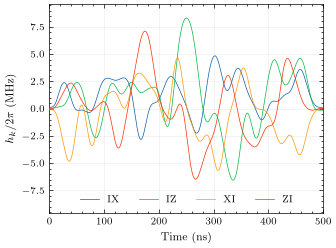

In [5]:
fig = plt.figure(figsize=(ONE_COLUMN, 3))
# Physical axes: time in ns, and each coefficient as a rate h / 2pi in MHz
# (for the sigma^x terms that is Omega / 4pi in the H = Omega/2 sigma^x convention).
gs = fig.add_gridspec(1, 1)
ax_pulse = fig.add_subplot(gs[0, 0])

time_ns = np.arange(L_LARGE) * DT * 1e9
to_mhz = 1 / DT / (2 * np.pi) / 1e6
final_mhz = polished * to_mhz
for k, label in enumerate(labels):
    ax_pulse.plot(time_ns, final_mhz[:, k], color=SCIENCEPLOT_COLOURS[k], lw=0.5,
                  zorder=3, label=label)
ax_pulse.set_xlim(0, T_GATE * 1e9)
# Headroom for the legend, which sits over the flat middle of the pulse.
span = float(np.abs(final_mhz).max())
ax_pulse.set_ylim(-1.15 * span, 1.15 * span)
ax_pulse.set_xlabel("Time (ns)")
ax_pulse.set_ylabel(r"$h_k / 2\pi$ (MHz)")
ax_pulse.grid(alpha=0.25, lw=0.4)
ax_pulse.legend(ncol=len(labels), loc="lower center",)

fig.subplots_adjust(left=0.15, right=0.955, top=0.88, bottom=0.185)
print(save_figure(fig, f"fig5_large_L_{TARGET_L}_L{L_LARGE}"))
plt.show()